In [1]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))
print("project root:", root)


project root: e:\Projects\biomed-ml


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, classification_report,
                             precision_score, recall_score)
from biomed.datasets import BonnEEGDataset
from biomed.features import StatsFeatures, BandPowerFeatures, CombinedFeatures
from biomed.models import MODELS
from biomed.evaluation import out_of_fold_proba

X, y, groups = BonnEEGDataset().load()
fe = CombinedFeatures([StatsFeatures(), BandPowerFeatures()])
F = fe.transform(X)
target = (y == 1).astype(int)

proba = out_of_fold_proba(MODELS["random_forest"], F, target, groups)
pred = (proba >= 0.5).astype(int)
print("done", proba.shape)


done (11500,)


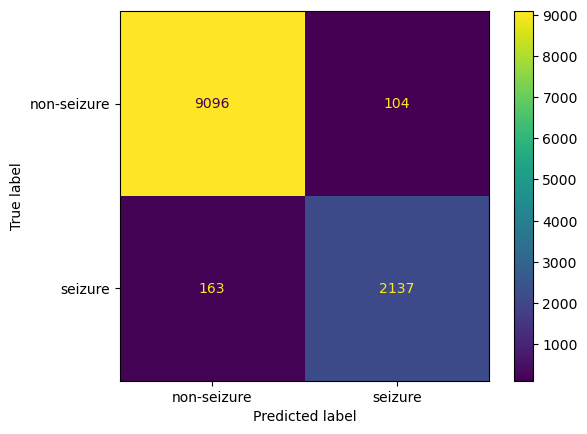

              precision    recall  f1-score   support

           0      0.982     0.989     0.986      9200
           1      0.954     0.929     0.941      2300

    accuracy                          0.977     11500
   macro avg      0.968     0.959     0.963     11500
weighted avg      0.977     0.977     0.977     11500



In [3]:
ConfusionMatrixDisplay.from_predictions(
    target, pred, display_labels=["non-seizure", "seizure"])
plt.show()
print(classification_report(target, pred, digits=3))


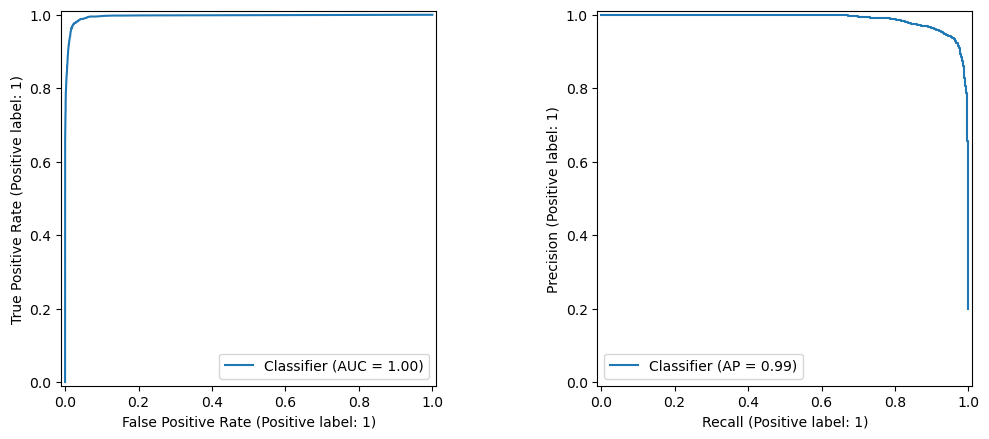

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(target, proba, ax=axes[0])
PrecisionRecallDisplay.from_predictions(target, proba, ax=axes[1])
plt.tight_layout()
plt.show()


In [5]:
names = {1: "Seizure", 2: "Tumor", 3: "Healthy", 4: "Closed", 5: "Open"}
by_class = pd.DataFrame({"y": y, "pred": pred}).groupby("y")["pred"].agg(["mean", "size"])
by_class.index = by_class.index.map(names)
by_class.columns = ["fraction predicted as seizure", "n"]
by_class.round(4)


,fraction predicted as seizure,n
y,,
Seizure,0.9291,2300
Tumor,0.0309,2300
Healthy,0.0126,2300
Closed,0.0017,2300
Open,0.0000,2300


In [6]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(target, p, zero_division=0),
                 "recall": recall_score(target, p)})
pd.DataFrame(rows).round(3)


,threshold,precision,recall
0,0.2,0.895,0.978
1,0.3,0.930,0.965
2,0.4,0.943,0.946
3,0.5,0.954,0.929
4,0.6,0.963,0.906
5,0.7,0.970,0.874
6,0.8,0.981,0.834


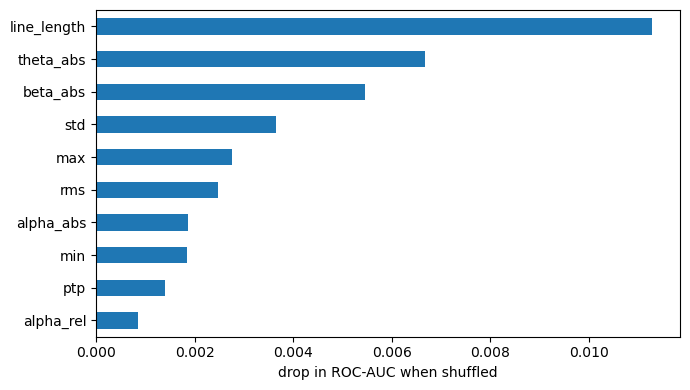

line_length       0.0113
theta_abs         0.0067
beta_abs          0.0055
std               0.0037
max               0.0028
rms               0.0025
alpha_abs         0.0019
min               0.0019
ptp               0.0014
alpha_rel         0.0009
delta_rel         0.0006
zero_crossings    0.0006
beta_rel          0.0004
gamma_abs         0.0001
skew              0.0001
gamma_rel         0.0001
dominant_freq     0.0001
theta_rel         0.0001
delta_abs         0.0001
mean              0.0000
kurtosis          0.0000
dtype: float64

In [7]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr, te = next(gss.split(F, target, groups))

model = MODELS["random_forest"]()
model.fit(F[tr], target[tr])
r = permutation_importance(model, F[te], target[te], scoring="roc_auc",
                           n_repeats=10, random_state=42, n_jobs=-1)

imp = pd.Series(r.importances_mean, index=fe.feature_names).sort_values(ascending=False)
imp.head(10)[::-1].plot.barh(figsize=(7, 4))
plt.xlabel("drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.show()
imp.round(4)
